In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import torch.nn as nn
import torch

import neurogym as ngym
from torch.nn import functional as F
from IPython.display import clear_output

from neurogym.core import TrialEnv
from neurogym.utils.ngym_random import TruncExp
from neurogym.utils import scheduler, spaces
from neurogym.wrappers.block import ScheduleEnvs
from neurogym.wrappers import Monitor
from neurogym.utils import plot_env

warnings.filterwarnings("ignore")
clear_output()

In [2]:
class SequencePerceptualDecisionMaking(TrialEnv):
    """Perceptual decision-making task.

    Two-alternative forced choice task where the agent integrates noisy stimuli
    to decide which option has a higher average value.

    The agent observes a noisy stimulus during the stimulus period, with varying
    coherence levels (signal strength). The correct response is the location with
    the stronger average evidence. There is not a specialized stimulus period, and the
    agent must respond quickly after the stimulus is presented.

    Args:
        dt: Timestep of the environment in milliseconds.
        dim_ring: Number of stimulus locations (or choices).
        rewards: Optional dictionary to override default rewards. The required keys are "abort",
            "correct", and "fail". Defaults to {"abort": -0.1, "correct": 1.0, "fail": 0.0}.
        timing: Optional dictionary to override default durations of task periods. The expected keys are
            "fixation", "stimulus" (required), "delay", and "decision" (required).
            Defaults to {"fixation": 100, "stimulus": 2000, "delay": 0, "decision": 100}.
        cohs: Optional list of coherence levels controlling task difficulty.
            Defaults to [0, 6.4, 12.8, 25.6, 51.2].
        sigma: Standard deviation of Gaussian noise added to stimulus.
        abort: If True, incorrect actions during fixation abort the trial.
    """

    metadata = {  # noqa: RUF012
        "paper_link": "https://www.jneurosci.org/content/12/12/4745",
        "paper_name": "The analysis of visual motion: a comparison of neuronal and psychophysical performance",
        "tags": ["perceptual", "two-alternative", "supervised"],
    }

    def __init__(
        self,
        dt: int = 100,
        dim_ring: int = 2,
        rewards: dict[str, float] | None = None,
        timing: dict[str, int | TruncExp] | None = None,
        cohs: list[float] | None = None,
        sigma: float = 0.2,
        abort: bool = False,
        n_stim: int = 6
    ) -> None:
        super().__init__(dt=dt)
        # print('Constructing PerceptualDecisionMaking environment with dt:', dt, 'ms')
        self.dt = dt
        self.dim_ring = dim_ring
        self.abort = abort

        self.rewards = {"abort": -0.1, "correct": 1.0, "fail": -0.5}
        if rewards:
            self.rewards.update(rewards)

        decision_time = 1200
        self.timing = {"fixation": 100, 'stimulus': decision_time, "delay": 0, "decision": decision_time}
        if timing:
            self.timing.update(timing)
        self.decision_idx = (self.timing['fixation'] + self.timing['stimulus'] + self.timing['delay'])//self.dt

        self.cohs = cohs or [6.4, 12.8, 19.2, 25.6]
        self.sigma = sigma / np.sqrt(self.dt)

        self.theta = np.linspace(0, 2 * np.pi, self.dim_ring, endpoint=False)
        self.choices = np.arange(self.dim_ring)

        self.n_stim = n_stim  # Number of stimuli to present
        self.time_per_stim = self.timing["stimulus"] // self.n_stim  # Time allocated for each stimulus

        # self.pattern_matrix = np.random.rand(self.dim_ring, self.dim_ring)
        self.pattern_matrix = np.eye(self.dim_ring)
        self.observation_space = spaces.Box(
            -np.inf,
            np.inf,
            shape=(1 + self.dim_ring,),
            dtype=np.float32,
            name={"fixation": 0, "stimulus": list(range(1, self.dim_ring + 1))},
        )
        self.action_space = spaces.Discrete(
            1 + self.dim_ring,
            name={"fixation": 0, "choice": list(range(1, self.dim_ring + 1))},
        )

    def _new_trial(self, **kwargs):
        """Generate a new trial with randomized ground truth and stimulus coherence.

        Sets up the trial timeline, generates a noisy stimulus centered around the
        ground truth direction, and assigns it to the appropriate observation period.
        """
        # trial = {
        #     "ground_truth": self.rng.choice(self.choices),
        #     "coh": self.rng.choice(self.cohs),
        # }


        for i in range(self.n_stim):
            self.timing[f"stimulus_{i}"] = self.time_per_stim
            self.timing[f"decision_{i}"] = self.time_per_stim

        ground_truth = self.rng.choice(self.choices, size=self.n_stim)
        coh = self.rng.choice(self.cohs, size=self.n_stim)

        trial = {
            "ground_truth": ground_truth,
            "coh": coh,
            "sigma": self.sigma,
        }
        trial.update(kwargs)

        gt = trial["ground_truth"]
        coh = trial["coh"]
        stim_theta = self.theta[gt]
        # print('gt:', gt)
        # print('stim_theta:', stim_theta)

        periods = ["fixation"] + [f"stimulus_{i}" for i in range(self.n_stim)] + [f"decision_{i}" for i in range(self.n_stim)]
        # print('periods:', periods)
        self.add_period(periods)
        self.add_ob(1, period="fixation", where="fixation")
        for i in range(self.n_stim):
            stim = np.cos(self.theta - stim_theta[i]) * (coh[i] / 200) + 0.5
            pattern = self.pattern_matrix @ stim
            self.add_ob(pattern, period=f"stimulus_{i}", where="stimulus")
            self.add_randn(0, self.sigma, period=f"stimulus_{i}", where="stimulus")
            self.set_groundtruth(gt[i], period=f"decision_{i}", where="choice")

        # print('tmax:', self._tmax)
        return trial

    def test_new_trial(self, choice, coh):
        self._tmax = 0  # reset, self.tmax not reset so it can be used in step
        self._ob_built = False
        self._gt_built = False

        trial = {"ground_truth": choice,
            "coh": coh}
        gt = trial["ground_truth"]
        stim_theta = self.theta[gt]
        self.add_period(["fixation", "stimulus", "delay", "decision"])
        self.add_ob(1, period="fixation", where="fixation")
        stim = np.cos(self.theta - stim_theta) * (coh / 200) + 0.5
        self.add_ob(stim, period="stimulus", where="stimulus")
        # print('stim:', stim)
        self.add_randn(0, self.sigma, period="stimulus", where="stimulus")
        # print('noisy stim:', self.view_ob("stimulus"))
        self.set_groundtruth(gt, period="decision", where="choice")

        self.trial = trial
        self.num_tr += 1  # Increment trial count
        self._has_gt = self._gt_built
        return trial

    def _step(self, action):
        """Execute a single time step of the environment.

        The agent must fixate during the fixation period and respond during
        the decision period. Incorrect actions may abort the trial or yield no reward.
        """
        new_trial = False
        reward = 0
        gt = self.gt_now
        # print('gt:', gt, 'action:', action)

        if self.in_period("fixation"):
            if action != 0:
                new_trial = self.abort
                reward += self.rewards["abort"]

        for i in range(self.n_stim):
            if self.in_period(f"decision_{i}"):
                if action != 0:
                    if action == gt:
                        reward += self.rewards["correct"]
                    else:
                        reward += self.rewards["fail"]
                if i == self.n_stim - 1:
                    new_trial = True
                break


        return (
            self.ob_now,
            reward,
            False,  # terminated
            False,  # truncated
            {"new_trial": new_trial, "gt": gt},
        )

Trial timing (in milliseconds):
{'fixation': 100, 'stimulus': 1200, 'delay': 0, 'decision': 1200}

Observation space structure:
Box(-inf, inf, (6,), float32)

Action space structure:
Discrete(6)
Action mapping:
{'fixation': 0, 'choice': [1, 2, 3, 4, 5]}


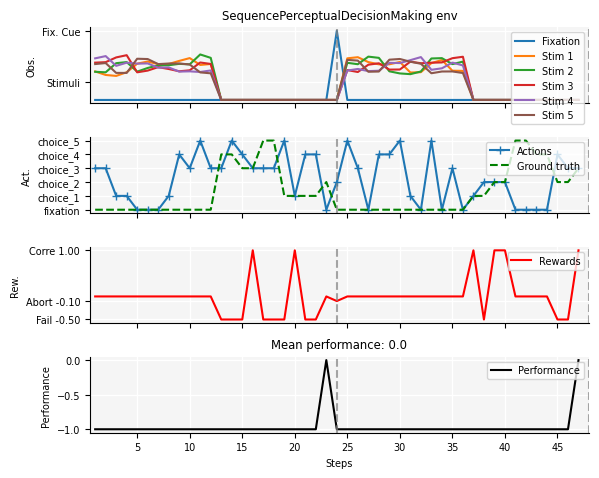

In [3]:
# Environment parameters
# This setting is low to speed up testing, we recommend setting it to at least 1000
dt = 100
dim_ring = 5  # Number of choices in the ring representation


kwargs = {'dt': dt, 'dim_ring': dim_ring}

env = SequencePerceptualDecisionMaking(**kwargs)

# Print environment specifications
print("Trial timing (in milliseconds):")
print(env.timing)

print("\nObservation space structure:")
print(env.observation_space)

print("\nAction space structure:")
print(env.action_space)
print("Action mapping:")
print(env.action_space.name)

obs, info = env.reset()

stims = [f'Stim {i}' for i in range(1, kwargs['dim_ring'] + 1)]
# Visualize example trials
fig = plot_env(
    env,
    name='SequencePerceptualDecisionMaking',
    ob_traces=['Fixation'] + stims,
    num_trials=2,
)

ob_size = env.observation_space.shape[0]
act_size = env.action_space.n

In [4]:
def test(env, net, num_trial=100, device='cuda:0'):
    net.eval()
    perf = 0
    for i in range(num_trial):
        env.new_trial()
        ob, gt = env.ob, env.gt
        # print('obs:', ob.shape, ob)
        # print('gt:', gt.shape, gt)
        ob = ob[:, np.newaxis, :]  # Add batch axis
        inputs = torch.from_numpy(ob).type(torch.float).to(device)
        action_pred = net(inputs)[0]
        action_pred = action_pred.cpu().detach().numpy()
        action_pred = np.argmax(action_pred, axis=-1)
        decision_idx = env.decision_idx
        perf += (gt[decision_idx:] == action_pred[decision_idx:,0]).mean()

    perf /= num_trial
    print('Average performance in {:d} trials: {:2f}'.format(num_trial, perf))
    return perf


def plot_test_performance(test_EI_acc, test_simple_acc, show_values=True):
    mean_ei = np.mean(test_EI_acc, axis=0)
    std_ei = np.std(test_EI_acc, axis=0)  # population std; use ddof=1 for sample std
    mean_simple = np.mean(test_simple_acc, axis=0)
    std_simple = np.std(test_simple_acc, axis=0)

    width = 0.35  # bar width

    fig, ax = plt.subplots(figsize=(4,4))
    bars = ax.bar(np.arange(2), [mean_ei, mean_simple], yerr=[std_ei, std_simple], width=width, capsize=4)
    ax.set_xticks(np.arange(2), labels=['EI', 'Simple'])
    # bars_ei = ax.bar(height=mean_ei, width=width,
    #                  yerr=std_ei, capsize=4,
    #                  label='EI')
    # bars_simple = ax.bar(height=mean_simple, width=width,
    #                      yerr=std_simple, capsize=4,
    #                      label='Simple')

    ax.set_ylabel('Test accuracy')
    # ax.set_title('Model comparison across environments')
    ax.legend()

    if show_values:
        ax.bar_label(bars, fmt='%.2f', padding=2)

    plt.tight_layout()
    # plt.savefig('./output/multitask/yang19_test_performance.png')
    plt.show()

In [5]:
from pdm_model import Net, SimpleNet
from pdm_train import train
n_seed = 5
epochs = 2000
lyapunov_every = 100
seq_len = 100
device = 'cuda:0'

test_EI_performance = np.zeros((n_seed, ))
test_simple_performance = np.zeros((n_seed, ))
loss_log_ei = np.zeros((n_seed, epochs, 3))
loss_log_simple = np.zeros((n_seed, epochs, 3))

gradient_log_ei = np.zeros((n_seed, epochs, 1))
gradient_log_simple = np.zeros((n_seed, epochs, 1))

spectral_radius_log_ei = np.zeros((n_seed, epochs, 1))
spectral_radius_log_simple = np.zeros((n_seed, epochs, 1))

rec_balance_log_ei = np.zeros((n_seed, epochs, seq_len))
rec_balance_log_simple = np.zeros((n_seed, epochs, seq_len))

hidden_size = 64

lyapunov_spectrum_log_ei = np.zeros((n_seed, epochs // lyapunov_every, hidden_size))  # Track Lyapunov spectrum for EI
lyapunov_spectrum_log_simple = np.zeros((n_seed, epochs // lyapunov_every, hidden_size))  # Track Lyapunov spectrum for simple


for seed in range(n_seed):
    print(f"Seed {seed + 1}/{n_seed}")
    torch.manual_seed(seed)
    np.random.seed(seed)

    # Create the model

    net = Net(ob_size=ob_size, num_h=hidden_size, act_size=act_size, entropy_loss=True).to(device)
    simple_net = SimpleNet(ob_size=ob_size, num_h=hidden_size, act_size=act_size).to(device)

    net, loss_log, gradient_log, spectral_radius_log, rec_balance_log, lyanpunov_spectrum_log = train(env, net, epochs, lyapunov_every)
    loss_log_ei[seed, :, :] = loss_log
    gradient_log_ei[seed, :, :] = gradient_log
    spectral_radius_log_ei[seed, :, :] = spectral_radius_log
    rec_balance_log_ei[seed, :, :] = rec_balance_log
    lyapunov_spectrum_log_ei[seed, :, :] = lyanpunov_spectrum_log
    simple_net, loss_log, gradient_log, spectral_radius_log, rec_balance_log, lyanpunov_spectrum_log = train(env, simple_net, epochs, lyapunov_every)
    loss_log_simple[seed, :, :] = loss_log
    gradient_log_simple[seed, :, :] = gradient_log
    spectral_radius_log_simple[seed, :, :] = spectral_radius_log
    rec_balance_log_simple[seed, :, :] = rec_balance_log
    lyapunov_spectrum_log_simple[seed, :, :] = lyanpunov_spectrum_log

    test_EI_performance[seed] = test(env, net)
    test_simple_performance[seed] = test(env, simple_net)

Seed 1/5
Epoch [0/2000], Loss: 2.2974
Epoch [100/2000], Loss: 2.0473
Epoch [200/2000], Loss: 1.9264
Epoch [300/2000], Loss: 1.8309
Epoch [400/2000], Loss: 1.7706
Epoch [500/2000], Loss: 1.7053
Epoch [600/2000], Loss: 1.6747
Epoch [700/2000], Loss: 1.6366
Epoch [800/2000], Loss: 1.6033
Epoch [900/2000], Loss: 1.5889
Epoch [1000/2000], Loss: 1.5762
Epoch [1100/2000], Loss: 1.5694
Epoch [1200/2000], Loss: 1.5510
Epoch [1300/2000], Loss: 1.5395
Epoch [1400/2000], Loss: 1.5249
Epoch [1500/2000], Loss: 1.5213
Epoch [1600/2000], Loss: 1.5193
Epoch [1700/2000], Loss: 1.5167
Epoch [1800/2000], Loss: 1.5015
Epoch [1900/2000], Loss: 1.4998
Finished Training
Epoch [0/2000], Loss: 1.7925
Epoch [100/2000], Loss: 1.3235
Epoch [200/2000], Loss: 1.0718
Epoch [300/2000], Loss: 1.0187
Epoch [400/2000], Loss: 0.9826
Epoch [500/2000], Loss: 0.9615
Epoch [600/2000], Loss: 0.9524
Epoch [700/2000], Loss: 0.9801
Epoch [800/2000], Loss: 0.9724
Epoch [900/2000], Loss: 0.9373
Epoch [1000/2000], Loss: 0.9219
Epoch

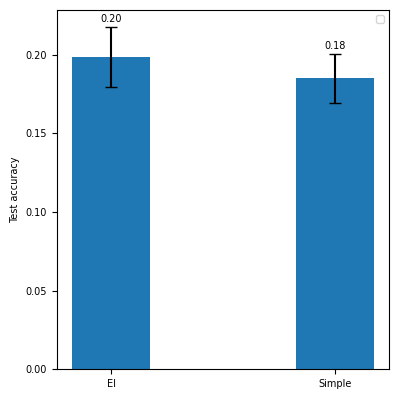

In [6]:
plot_test_performance(test_EI_performance, test_simple_performance, show_values=True)

In [7]:
from pdm_train import plot_loss_curve, plot_lyapunov_spectrum

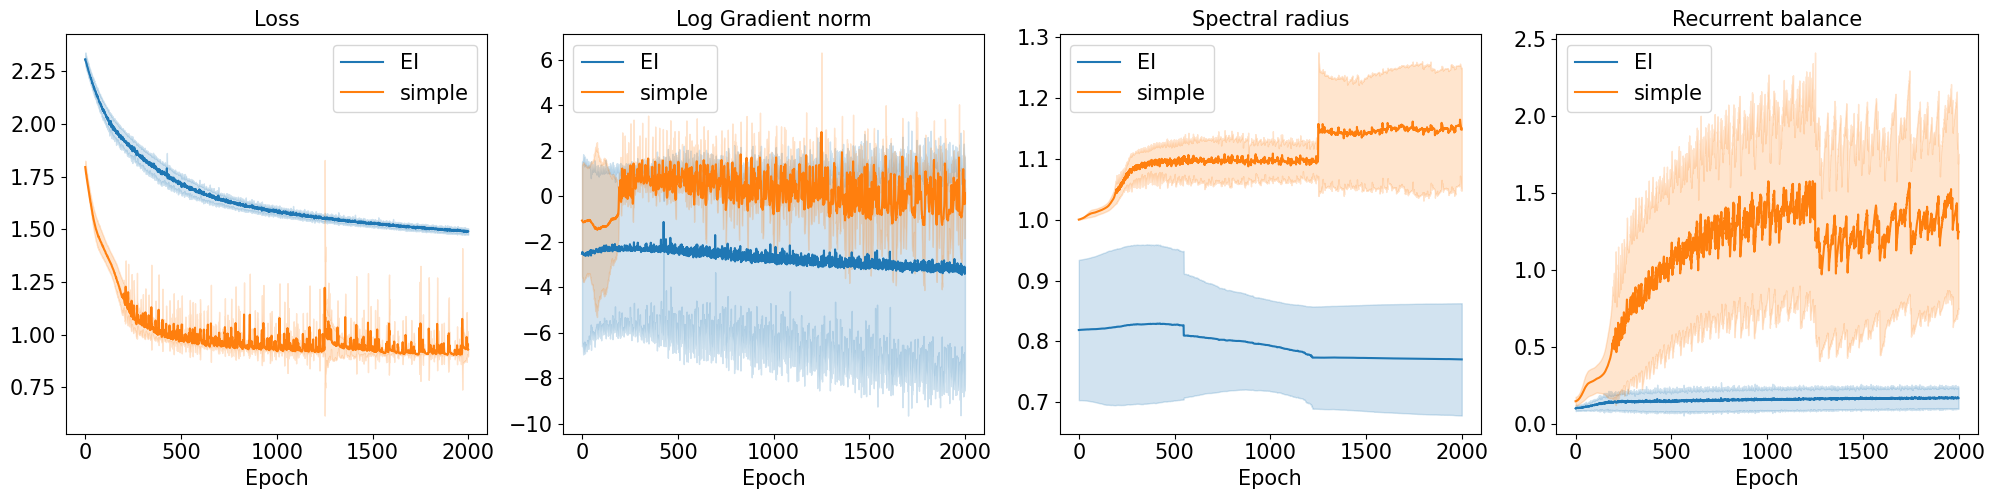

In [8]:
plot_loss_curve(loss_log_ei, gradient_log_ei,
                loss_log_simple, gradient_log_simple,
                spectral_radius_log_ei, spectral_radius_log_simple,
                rec_balance_log_ei, rec_balance_log_simple)

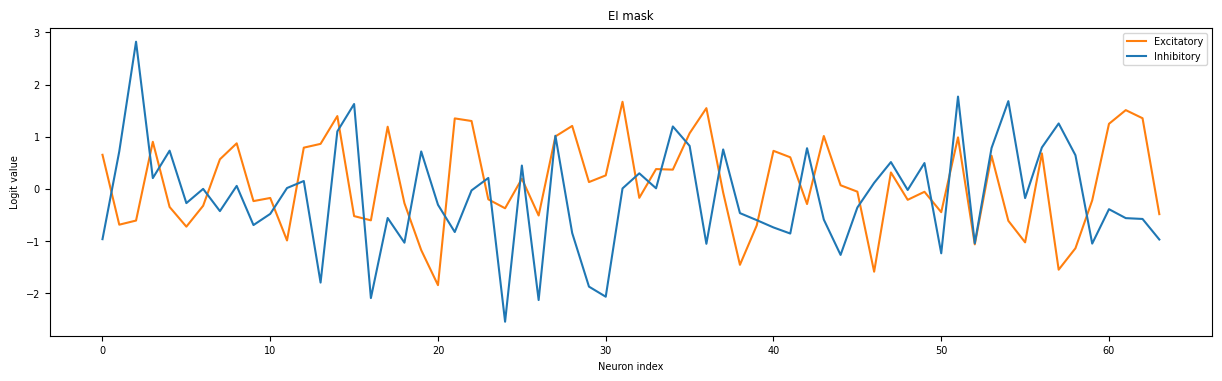

In [9]:
eimask = net.lstm.eimask_logit.detach().cpu().numpy()
ei_code = np.where(eimask[:, 0] > eimask[:, 1], 1., -1.)
mask = np.where(ei_code.reshape(-1,1)>0, np.array([[1,0]]).repeat(eimask.shape[0], axis=0),
                np.array([[0,1]]).repeat(eimask.shape[0], axis=0))
fig, ax = plt.subplots(1,1,figsize=(15, 4))
ax.plot(eimask[:, 0], label='Excitatory', color='C1')
ax.plot(eimask[:, 1], label='Inhibitory', color='C0')
ax.set_title('EI mask')
ax.set_xlabel('Neuron index')
ax.set_ylabel('Logit value')
ax.legend()
plt.show()

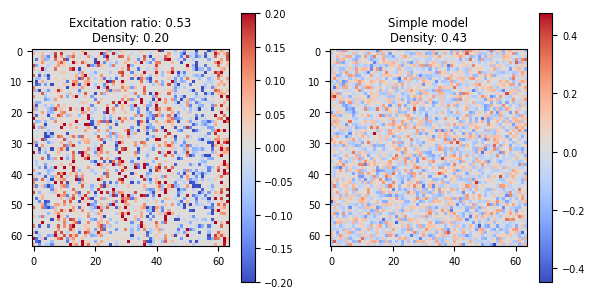

In [10]:
weight = net.get_actual_weight().detach().cpu().numpy()
fig, ax = plt.subplots(1,2,figsize=(6,3))
im = ax[0].imshow(weight, cmap='coolwarm', vmin=-0.2, vmax=0.2)
density = np.mean(np.abs(weight)>0.1)
eimask = net.lstm.eimask_logit.detach().cpu().numpy()
# mask = F.gumbel_softmax(net.lstm.eimask_logit, tau=0.1, hard=False, dim=-1).detach().cpu().numpy()
exc_ratio = np.mean(eimask[:, 0] > eimask[:, 1])
ax[0].set_title(f'Excitation ratio: {exc_ratio:.2f}\nDensity: {density:.2f}')
plt.colorbar(im, ax=ax[0])

weight_simple = simple_net.get_actual_weight().detach().cpu().numpy()
im = ax[1].imshow(weight_simple, cmap='coolwarm')
density_simple = np.mean(np.abs(weight_simple)>0.1)
ax[1].set_title(f'Simple model\nDensity: {density_simple:.2f}')
plt.colorbar(im, ax=ax[1])
plt.tight_layout()


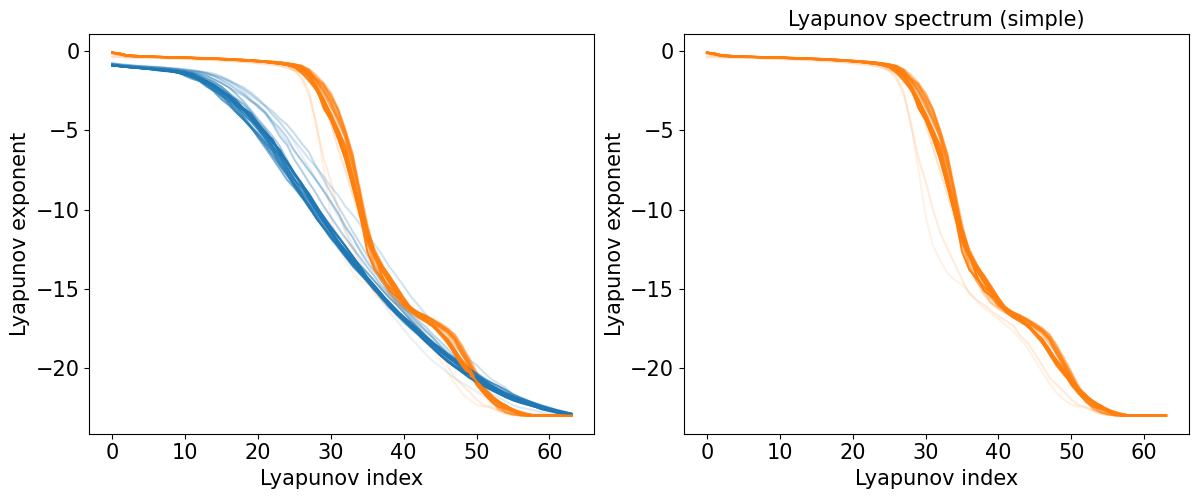

In [11]:
plot_lyapunov_spectrum(lyapunov_spectrum_log_ei, lyapunov_spectrum_log_simple)